# 03 · Modelado supervisado: predicción de churn a 90 días
**Proyecto final · Análisis de datos, BI y aprendizaje computacional**

## Qué se busca (y qué no)
El churn histórico es alto (55–70 % según el momento), así que **marcar a muchos no sirve**. Este notebook construye un modelo para **ordenar a los suscriptores por riesgo** y ayudar a decidir a quién atender primero, y lo evalúa con criterios honestos:

1. **Contra un modelo base** sin comportamiento (tipo de entrada, producto e historial). Si el modelo completo no lo supera, el comportamiento no aporta.
2. **Priorización con capacidad limitada:** precisión y lift en el 10–30 % de mayor riesgo.
3. **Calibración:** que "80 % de riesgo" signifique de verdad 80 %.
4. **Valor:** costo-beneficio con supuestos explícitos.

## Diseño de la validación (sin fuga de información)
- Cada ciclo se observa a **4, 3, 2 y 1 mes** de su vencimiento y solo usa datos anteriores a esa fecha.
- Se **excluyen los usuarios que ya pagaron** la renovación a esa fecha.
- **Partición temporal:** entrenamiento con ciclos que vencen hasta oct-2025 · calibración nov-2025 a ene-2026 · **prueba mayo–jul 2026** (ciclos cuyo resultado se conoció después).
- Algoritmos de clase: regresión logística, KNN, SVM, árbol de decisión y boosting. Métricas: ROC-AUC, PR-AUC, precisión, exhaustividad (recall) y F1.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, precision_recall_fscore_support

RAIZ = Path("..").resolve(); sys.path.append(str(RAIZ))
from src import features
PROC = RAIZ / "data" / "processed"; FIG = RAIZ / "resultados" / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
AZUL, ROJO, GRIS = "#2F6DB5", "#B3261E", "#8A94A0"
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 200, "display.max_columns", 60)

snap = pd.read_csv(PROC / "fact_snapshot_mensual.csv")
ciclos = pd.read_csv(PROC / "fact_ciclo.csv", dtype={"productoid": str, "ordenid": str},
                     parse_dates=["ciclo_inicio", "ciclo_fin", "fecha_pago", "inicio_renovacion", "fecha_pago_renovacion"])
BASES = {h: features.base_horizonte(snap, ciclos, d) for h, d in features.HORIZONTES.items()}
COLS = features.columnas_modelo(BASES[3]); CAT = features.CAT
NUM = [c for c in COLS if c not in CAT]
BASE_COLS = ["tipo_entrada", "productoid", "prev_tipo_entrada", "ciclos_previos", "duracion_dias", "numero_ciclo"]

def particion(b):
    fit = b[b["ciclo_fin"] <= "2025-10-31"]
    cal = b[(b["ciclo_fin"] > "2025-10-31") & (b["ciclo_fin"] <= "2026-01-31")]
    test = b[(b["ciclo_fin"] >= "2026-05-01") & (b["ciclo_fin"] <= "2026-07-31")]
    return fit, cal, test
pd.DataFrame({h: dict(zip(["entrenamiento", "calibración", "prueba"], map(len, particion(b)))) | {"churn prueba": round(particion(b)[2]["churn90"].mean(), 3)}
              for h, b in BASES.items()}).T.rename_axis("meses antes del vencimiento")

,entrenamiento,calibración,prueba,churn prueba
meses antes del vencimiento,,,,
4,57196.0,5279.0,4117.0,0.629
3,55745.0,5195.0,4074.0,0.635
2,52650.0,5094.0,3872.0,0.669
1,49025.0,4647.0,3606.0,0.718


## 1. Punto de partida: ¿qué tan bien "adivina" un modelo trivial?
Con un churn de 55–70 %, decir "todos se van" da 55–70 % de exactitud sin aprender nada. Por eso **la exactitud no se usa**: se mide qué tan bien se ordenan los usuarios (ROC-AUC, PR-AUC y lift).

## 2. Comparación de algoritmos (horizonte de 2 meses)
Se comparan los modelos vistos en clase con el mismo conjunto de variables. KNN y SVM son costosos, así que se entrenan con una muestra de 8.000 ciclos.

In [2]:
def prep_lineal():
    return ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore", min_frequency=30), CAT),
                              ("n", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM)])
def prep_arbol():
    return ColumnTransformer([("c", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT)], remainder="passthrough")

def modelos():
    return {
        "Regresión logística": make_pipeline(prep_lineal(), LogisticRegression(max_iter=500, C=0.5)),
        "KNN (k=75)": make_pipeline(prep_lineal(), KNeighborsClassifier(n_neighbors=75, weights="distance")),
        "SVM (kernel RBF)": make_pipeline(prep_lineal(), SVC(C=1.0, probability=True, random_state=0)),
        "Árbol (profundidad 6)": make_pipeline(prep_arbol(), SimpleImputer(strategy="median"), DecisionTreeClassifier(max_depth=6, min_samples_leaf=100, random_state=0)),
        "Boosting (HistGradientBoosting)": make_pipeline(prep_arbol(), HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_depth=5, min_samples_leaf=40, l2_regularization=1.0, random_state=0)),
    }

def preparar(df, cols):
    X = df[cols].copy()
    for k in CAT:
        if k in X: X[k] = X[k].astype(str)
    return X

def lift_top(y, p, q):
    n = int(len(y) * q); idx = np.argsort(-np.asarray(p))[:n]
    return np.asarray(y)[idx].mean(), np.asarray(y)[idx].mean() / np.mean(y)

H = 2
fit, cal, test = particion(BASES[H])
entrena = pd.concat([fit, cal])
muestra = entrena.sample(8000, random_state=0)
filas = []
for nombre, m in modelos().items():
    tr = muestra if nombre in ("KNN (k=75)", "SVM (kernel RBF)") else entrena
    m.fit(preparar(tr, COLS), tr["churn90"]); p = m.predict_proba(preparar(test, COLS))[:, 1]
    pr, lf = lift_top(test["churn90"], p, 0.2)
    filas.append({"modelo": nombre, "ROC-AUC": roc_auc_score(test["churn90"], p), "PR-AUC": average_precision_score(test["churn90"], p),
                  "precisión top 20 %": pr, "lift top 20 %": lf})
comp = pd.DataFrame(filas).set_index("modelo").round(3)
print(f"Churn en la prueba (referencia de PR-AUC y de precisión): {test['churn90'].mean():.3f}")
comp

Churn en la prueba (referencia de PR-AUC y de precisión): 0.669


,ROC-AUC,PR-AUC,precisión top 20 %,lift top 20 %
modelo,,,,
Regresión logística,0.578,0.746,0.789,1.181
KNN (k=75),0.591,0.756,0.826,1.235
SVM (kernel RBF),0.584,0.742,0.787,1.177
Árbol (profundidad 6),0.614,0.764,0.855,1.279
Boosting (HistGradientBoosting),0.665,0.806,0.867,1.297


**Lectura:** el boosting suele ganar porque captura interacciones y trata bien los valores faltantes y los conteos con muchos ceros. KNN y SVM sufren con tantas variables dispersas. La regresión logística queda como **referencia interpretable**. Se continúa con el boosting.

## 3. ¿El comportamiento aporta más allá del contexto del ciclo?
Se entrena el mismo boosting solo con tipo de entrada, producto e historial de ciclos (**modelo base**) y se compara con el **modelo completo**, en los cuatro horizontes y dentro de cada tipo de entrada.

In [3]:
def boosting(): return modelos()["Boosting (HistGradientBoosting)"]
res, pred = [], {}
for h, b in BASES.items():
    fit, cal, test = particion(b); ent = pd.concat([fit, cal]); y = test["churn90"]
    mb = boosting().fit(preparar(ent, BASE_COLS), ent["churn90"]); pb = mb.predict_proba(preparar(test, BASE_COLS))[:, 1]
    mf = boosting().fit(preparar(ent, COLS), ent["churn90"]);      pf = mf.predict_proba(preparar(test, COLS))[:, 1]
    pred[h] = test.assign(p_base=pb, p_full=pf)
    for nombre, p in (("base", pb), ("completo", pf)):
        pr10, lf10 = lift_top(y, p, 0.1); pr20, lf20 = lift_top(y, p, 0.2)
        seguro = y.iloc[np.argsort(p)[: int(len(y) * 0.2)]].mean()
        res.append({"meses": h, "modelo": nombre, "ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
                    "precisión top 10 %": pr10, "precisión top 20 %": pr20, "lift top 20 %": lf20,
                    "churn del 20 % más seguro": seguro, "churn real": y.mean()})
tabla = pd.DataFrame(res).round(3)
tabla.set_index(["meses", "modelo"])

ROC-AUC  PR-AUC  precisión top 10 %  precisión top 20 %  lift top 20 %  churn del 20 % más seguro  churn real
meses modelo                                                                                                                 
4     base        0.646   0.755               0.854               0.817          1.298                      0.505       0.629
      completo    0.691   0.792               0.910               0.852          1.354                      0.418       0.629
3     base        0.646   0.760               0.875               0.833          1.311                      0.471       0.635
      completo    0.671   0.787               0.919               0.866          1.363                      0.461       0.635
2     base        0.665   0.791               0.886               0.831          1.242                      0.453       0.669
      completo    0.665   0.806               0.933               0.867          1.297                      0.517       0.669
1     base        0.681   0.831               0.911               0.868          1.209                      0.491       0.718
      completo    0.702   0.860               0.953               0.936          1.304                      0.540       0.718

In [4]:
filas = []
for h, t in pred.items():
    for seg in ["NUEVA", "REACTIVACION", "RENOVACION", "UPGRADE"]:
        d = t[t["tipo_entrada"] == seg]
        if len(d) > 200 and d["churn90"].nunique() > 1:
            filas.append({"meses": h, "tipo de entrada": seg, "n": len(d), "churn": d["churn90"].mean(),
                          "AUC base": roc_auc_score(d["churn90"], d["p_base"]), "AUC completo": roc_auc_score(d["churn90"], d["p_full"])})
seg = pd.DataFrame(filas).round(3); seg["mejora"] = (seg["AUC completo"] - seg["AUC base"]).round(3)
seg.pivot(index="tipo de entrada", columns="meses", values=["AUC base", "AUC completo", "mejora"])

AUC base                      AUC completo                      mejora                     
meses                  1      2      3      4            1      2      3      4      1      2      3      4
tipo de entrada                                                                                            
NUEVA              0.633  0.648  0.648  0.640        0.707  0.679  0.702  0.694  0.074  0.031  0.054  0.054
REACTIVACION       0.654  0.634  0.620  0.642        0.646  0.628  0.629  0.650 -0.008 -0.006  0.009  0.008
RENOVACION         0.703  0.680  0.635  0.611        0.724  0.649  0.650  0.682  0.021 -0.031  0.015  0.071

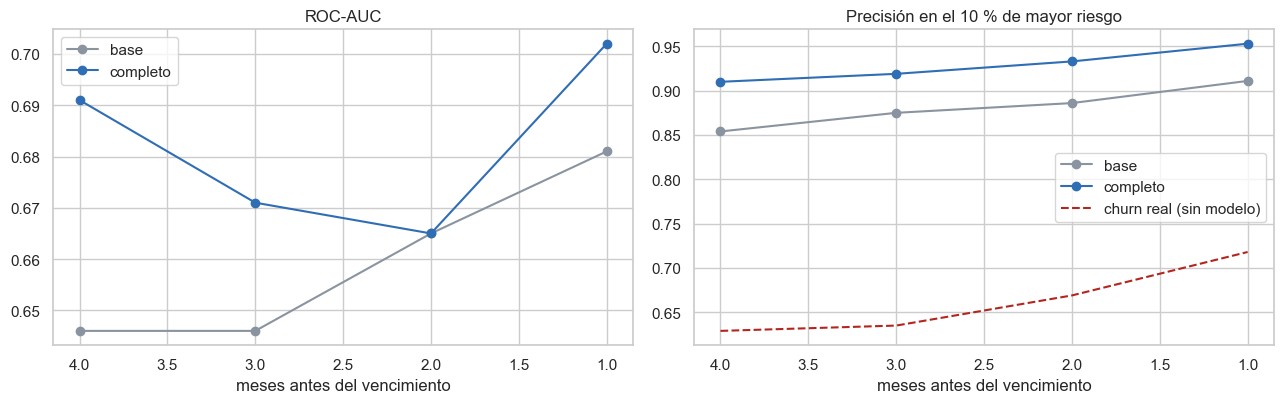

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for nombre, color in (("base", GRIS), ("completo", AZUL)):
    t = tabla[tabla["modelo"] == nombre]
    ax[0].plot(t["meses"], t["ROC-AUC"], marker="o", color=color, label=nombre)
    ax[1].plot(t["meses"], t["precisión top 10 %"], marker="o", color=color, label=nombre)
ax[1].plot(tabla[tabla["modelo"] == "base"]["meses"], tabla[tabla["modelo"] == "base"]["churn real"], ls="--", color=ROJO, label="churn real (sin modelo)")
for a, t in zip(ax, ["ROC-AUC", "Precisión en el 10 % de mayor riesgo"]):
    a.set_title(t); a.set_xlabel("meses antes del vencimiento"); a.invert_xaxis(); a.legend()
plt.tight_layout(); plt.savefig(FIG / "modelo_base_vs_completo.png", dpi=130); plt.show()

**Lectura honesta:** el modelo completo supera al base de forma **irregular**: +0,045 de ROC-AUC a 4 meses, +0,025 a 3, nada a 2 y +0,02 a 1 mes. Lo que sí se ve en todos los horizontes es que mejora la **parte alta de la lista**: la precisión en el 10 % de mayor riesgo sube de 85–91 % (base) a 91–95 % (completo). Por tipo de entrada, el comportamiento ayuda de forma consistente en **altas nuevas** (+0,03 a +0,07 de AUC); en renovaciones es irregular y en **reactivaciones no aporta**. El tipo de entrada, el producto y el historial ya explican buena parte del riesgo; el comportamiento afina.

## 4. Calibración
Los ciclos de prueba tienen **más churn** que los de entrenamiento (en parte porque se retiran quienes ya pagaron, y en parte por un cambio real del período). Se prueba una regresión isotónica ajustada sobre el período de calibración (nov-2025 a ene-2026), el más reciente disponible, para ver si corrige el nivel de riesgo.

Churn real en prueba: 0.669 | predicho sin calibrar: 0.630 | predicho calibrado: 0.622
Brier sin calibrar: 0.2207 | calibrado: 0.2198 | referencia (prevalencia): 0.2216


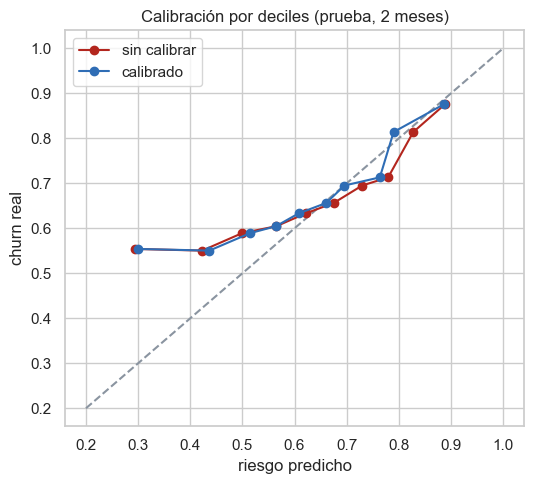

,sin calibrar,calibrado,real
0,0.294,0.299,0.554
1,0.423,0.437,0.550
2,0.499,0.515,0.589
3,0.565,0.564,0.605
4,0.621,0.608,0.633
5,0.675,0.661,0.656
6,0.730,0.696,0.695
7,0.779,0.764,0.713
8,0.828,0.790,0.814
9,0.889,0.887,0.876


In [6]:
H = 2
b = BASES[H]; fit, cal, test = particion(b)
m = boosting().fit(preparar(fit, COLS), fit["churn90"])
p_cal = m.predict_proba(preparar(cal, COLS))[:, 1]; p_test = m.predict_proba(preparar(test, COLS))[:, 1]
iso = IsotonicRegression(out_of_bounds="clip").fit(p_cal, cal["churn90"])
p_iso = iso.predict(p_test); y = test["churn90"]
print(f"Churn real en prueba: {y.mean():.3f} | predicho sin calibrar: {p_test.mean():.3f} | predicho calibrado: {p_iso.mean():.3f}")
print(f"Brier sin calibrar: {brier_score_loss(y, p_test):.4f} | calibrado: {brier_score_loss(y, p_iso):.4f} | referencia (prevalencia): {brier_score_loss(y, np.full(len(y), y.mean())):.4f}")

dec = pd.qcut(pd.Series(p_test).rank(method="first"), 10, labels=False)
rel = pd.DataFrame({"sin calibrar": pd.Series(p_test).groupby(dec).mean(), "calibrado": pd.Series(p_iso).groupby(dec).mean(), "real": pd.Series(y.values).groupby(dec).mean()})
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0.2, 1], [0.2, 1], color=GRIS, ls="--"); ax.plot(rel["sin calibrar"], rel["real"], marker="o", color=ROJO, label="sin calibrar"); ax.plot(rel["calibrado"], rel["real"], marker="o", color=AZUL, label="calibrado")
ax.set_xlabel("riesgo predicho"); ax.set_ylabel("churn real"); ax.set_title("Calibración por deciles (prueba, 2 meses)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "modelo_calibracion.png", dpi=130); plt.show()
rel.round(3)

**Lectura:** la isotónica casi no corrige: el modelo predice 63 % y el real fue 67 %. La diferencia no es de forma de la curva sino un **cambio de nivel en el tiempo** (deriva): mayo–julio de 2026 tiene más churn que los períodos anteriores. El **orden** se mantiene en la parte alta (el decil más riesgoso: 89 % predicho, 88 % real), pero en la parte baja el modelo es demasiado optimista: el decil "más seguro" se predice en 30 % y en realidad se fue el 55 %. Es decir, **no hay un grupo realmente seguro**; incluso los de menor riesgo se van más de la mitad de las veces. Un modelo honesto lo dice: sirve para priorizar, no para prometer un porcentaje exacto, y debe recalibrarse cada mes.

## 5. Qué variables importan
Importancia por permutación sobre la prueba: cuánto cae el ROC-AUC al desordenar cada variable. Es más fiable que la importancia interna del árbol.

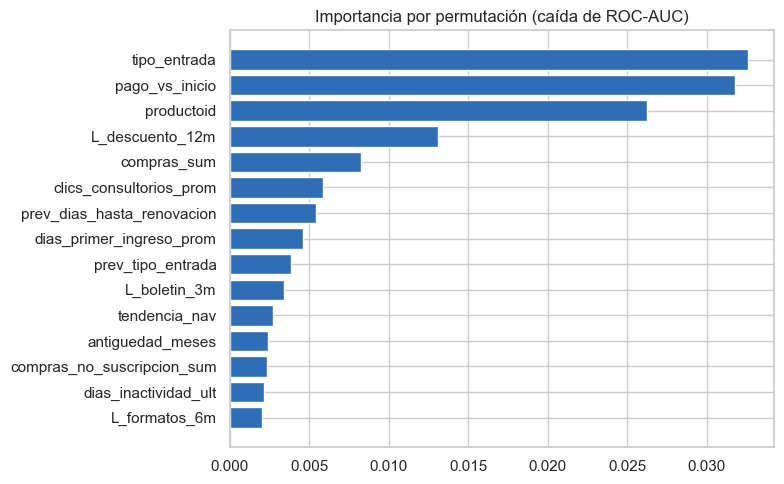

,caída de AUC
tipo_entrada,0.0326
pago_vs_inicio,0.0318
productoid,0.0262
L_descuento_12m,0.0131
compras_sum,0.0083
clics_consultorios_prom,0.0059
prev_dias_hasta_renovacion,0.0054
dias_primer_ingreso_prom,0.0046
prev_tipo_entrada,0.0038
L_boletin_3m,0.0034


In [7]:
Xt = preparar(test, COLS)
imp = permutation_importance(m, Xt, y, scoring="roc_auc", n_repeats=4, random_state=0, n_jobs=1)
imp = pd.Series(imp.importances_mean, index=COLS).sort_values(ascending=False)
top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5)); ax.barh(top.index, top.values, color=AZUL); ax.set_title("Importancia por permutación (caída de ROC-AUC)")
plt.tight_layout(); plt.savefig(FIG / "modelo_importancia.png", dpi=130); plt.show()
imp.head(10).round(4).to_frame("caída de AUC")

## 6. ¿Qué se hace con el resultado?
Un modelo que dice "casi todos se van" no sirve. Lo útil es **separar** a los suscriptores en grupos con riesgos realmente distintos y saber **por qué**. Esta sección traduce el modelo a información de decisión.

### 6.1 ¿Cuánta lista hay que trabajar para detectar a la mayoría de los que se van?
Se ordena a los usuarios por riesgo y se mide qué porcentaje de quienes realmente se van queda dentro del primer X % de la lista. Una lista al azar capturaría exactamente X %; la diferencia es lo que aporta el modelo.

In [8]:
filas = []
for h, t in pred.items():
    yv = t["churn90"].values; o = np.argsort(-t["p_full"].values); ys = yv[o]; tot = yv.sum(); n = len(yv)
    fila = {"meses": h}
    for meta in (0.5, 0.7, 0.8):
        k = np.searchsorted(np.cumsum(ys) / tot, meta) + 1
        fila[f"lista para detectar {int(meta*100)} %"] = k / n
    for q in (0.2, 0.4):
        fila[f"detectado con el {int(q*100)} % de la lista"] = ys[: int(n * q)].sum() / tot
    filas.append(fila)
det = pd.DataFrame(filas).set_index("meses")
det.map(lambda v: f"{v:.0%}")

,lista para detectar 50 %,lista para detectar 70 %,lista para detectar 80 %,detectado con el 20 % de la lista,detectado con el 40 % de la lista
meses,,,,,
4,40%,60%,71%,27%,50%
3,41%,62%,73%,27%,49%
2,42%,63%,75%,26%,48%
1,42%,62%,73%,26%,48%


**Lectura:** el modelo mejora sobre el azar pero no hace magia: para detectar al 70–80 % de quienes se van hay que trabajar entre el 60 % y el 75 % de la lista. Por eso la lista **no se debe usar como "contactar a los que se van a ir"**, sino para **priorizar el orden y la intensidad** de la acción.

### 6.2 Tres niveles de riesgo
Se divide a los usuarios (por posición en el ranking) en **alto** (25 % superior), **medio** (50 % central) y **bajo** (25 % inferior), con el modelo de 2 meses.

In [9]:
t = pred[2].copy()
t["nivel"] = pd.qcut(t["p_full"].rank(method="first", ascending=False), [0, .25, .75, 1], labels=["Alto", "Medio", "Bajo"])
tot_churn = t["churn90"].sum()
niv = t.groupby("nivel", observed=True).agg(usuarios=("churn90", "size"), churn_real=("churn90", "mean"), se_van=("churn90", "sum"))
niv["% de la lista"] = niv["usuarios"] / niv["usuarios"].sum()
niv["% de los que se van"] = niv["se_van"] / tot_churn
niv["se quedan"] = niv["usuarios"] - niv["se_van"]
niv.round(3)

,usuarios,churn_real,se_van,% de la lista,% de los que se van,se quedan
nivel,,,,,,
Alto,968,0.846,819.0,0.25,0.316,149.0
Medio,1936,0.653,1265.0,0.50,0.489,671.0
Bajo,968,0.522,505.0,0.25,0.195,463.0


### 6.3 ¿Por qué están en cada nivel?
Perfil promedio de cada nivel con las variables que más pesan en el modelo. Sirve para **explicar** el riesgo y diseñar la acción de cada grupo.

In [10]:
perfil = t.groupby("nivel", observed=True).agg(
    pct_alta_nueva=("tipo_entrada", lambda x: (x == "NUEVA").mean()),
    pct_reactivacion=("tipo_entrada", lambda x: (x == "REACTIVACION").mean()),
    pct_renovacion=("tipo_entrada", lambda x: (x == "RENOVACION").mean()),
    ciclos_previos=("ciclos_previos", "mean"),
    antiguedad_meses=("antiguedad_meses", "median"),
    nav_media_dias=("nav_media", "mean"),
    pct_sin_foto_previa=("sin_foto_previa", "mean"),
    pagó_antes_de_empezar_dias=("pago_vs_inicio", "median"),
).round(2)
perfil.T

nivel,Alto,Medio,Bajo
pct_alta_nueva,0.60,0.15,0.03
pct_reactivacion,0.25,0.44,0.21
pct_renovacion,0.14,0.38,0.68
ciclos_previos,0.69,1.64,2.23
antiguedad_meses,13.00,39.00,52.00
nav_media_dias,1.04,1.53,2.08
pct_sin_foto_previa,0.00,0.00,0.01
pagó_antes_de_empezar_dias,0.00,0.00,8.00


**Cómo se leen los niveles**
- **Alto (25 % de la lista, 85 % de churn):** en su mayoría **altas nuevas** (60 %), con menos de un año de antigüedad y sin ciclos previos. Aquí se concentra el 32 % de quienes se van. Acción: **acompañamiento de la primera renovación** (onboarding, uso temprano, contacto antes del vencimiento).
- **Medio (50 %, 65 % de churn):** mezcla de reactivaciones y renovaciones. Acción: comunicación estándar de renovación y ofertas automáticas.
- **Bajo (25 %, 52 % de churn):** renovaciones con 2 o más ciclos y más uso. Es el grupo de menor riesgo pero **aun así más de la mitad no renueva** a 90 días; no hay un grupo seguro. Acción: bajo costo (automático).
- Los niveles se explican sobre todo por el **tipo de entrada y la antigüedad**; el uso reciente afina dentro de cada grupo.

### 6.4 Lo que se observa del contacto comercial (solo descriptivo)
El registro de contactos (`contacto_mes`) solo existe **desde febrero de 2026**, por eso no puede ser variable del modelo (no hay histórico para aprender de ella) y aquí se usa solo para describir. Comparación del churn entre contactados y no contactados **dentro de cada nivel**. Ojo: comercial contacta a quienes ya parecen en riesgo, así que esta tabla **no mide el efecto** de contactar; sirve para ver cuánta actividad hay hoy en cada nivel y para diseñar el experimento.

In [11]:
t["contactado"] = np.where(t["contactos_n"] > 0, "Contactado", "No contactado")
t.groupby(["nivel", "contactado"], observed=True)["churn90"].agg(["size", "mean"]).round(3).unstack()

size                     mean              
contactado Contactado No contactado Contactado No contactado
nivel                                                       
Alto               32           936      0.906         0.844
Medio              97          1839      0.588         0.657
Bajo               51           917      0.412         0.528

En los niveles medio y bajo, los contactados se van menos (59 % contra 66 % y 41 % contra 53 %), pero son pocos casos y **no sabemos si es efecto del contacto o de a quién se contacta**. En el nivel alto casi nadie recibió contacto registrado, que es justamente donde hay más por ganar: es la primera oportunidad que muestra el modelo.

### 6.5 Valor esperado de contactar: costo-beneficio
El equipo comercial tiene capacidad limitada. Se compara **contactar a todos** frente a **contactar solo al top-k** por riesgo. No se tiene el precio por plan (hay muchos descuentos), por eso se trabaja en **unidades de "valor de un ciclo renovado"** con supuestos explícitos y editables:

- `RECUPERACION`: de los usuarios que se iban y se contactan, qué fracción se logra retener. **No se conoce**; solo un experimento controlado (A/B) puede medirla.
- `COSTO`: costo de un contacto como fracción del valor de un ciclo.

Regla de decisión: contactar si `riesgo × RECUPERACION > COSTO`.

In [12]:
RECUPERACION = 0.10     # supuesto: 10 % de quienes se iban se retienen al contactarlos
COSTO = 0.02            # supuesto: un contacto cuesta el 2 % del valor de un ciclo

def beneficio(p, k, rec=RECUPERACION, costo=COSTO):
    idx = np.argsort(-p)[: int(len(p) * k)]
    return float((p[idx] * rec - costo).sum())

ks = [0.05, 0.10, 0.20, 0.30, 0.50, 1.0]
tab = pd.DataFrame({"% contactado": [int(k * 100) for k in ks],
                    "contactos": [int(len(p_iso) * k) for k in ks],
                    "precisión (churn real entre contactados)": [lift_top(y, p_iso, k)[0] for k in ks],
                    "beneficio neto (ciclos)": [beneficio(p_iso, k) for k in ks]}).round(3)
display(tab)
sens = pd.DataFrame({f"recuperación {r:.0%}": {f"costo {c:.0%}": max([beneficio(p_iso, k, r, c) for k in ks]) for c in (0.01, 0.02, 0.05)} for r in (0.05, 0.10, 0.20)}).round(1)
print("Mejor beneficio neto posible según los supuestos (ciclos):"); sens

,% contactado,contactos,precisión (churn real entre contactados),beneficio neto (ciclos)
0,5,193,0.917,13.645
1,10,387,0.873,26.603
2,20,774,0.831,49.442
3,30,1161,0.804,71.253
4,50,1936,0.753,108.321
5,100,3872,0.669,163.371


Mejor beneficio neto posible según los supuestos (ciclos):


,recuperación 5%,recuperación 10%,recuperación 20%
costo 1%,81.7,202.1,442.9
costo 2%,43.0,163.4,404.2
costo 5%,-0.9,50.2,288.0


**Cómo leerlo:** si contactar es barato, contactar a casi todos sigue siendo rentable (con tanto churn base, casi todos tienen riesgo alto). El modelo agrega valor cuando la **capacidad es limitada** o el contacto es caro (con costo 5 % y recuperación 5 % el beneficio total es negativo, pero el top 10 % sigue siendo positivo): ahí concentra el esfuerzo donde el riesgo real es 85–95 %. Los números dependen por completo de `RECUPERACION`, que hoy es un supuesto.

## 7. Conclusiones de la etapa
- El modelo **ordena** razonablemente la parte alta de la lista (el 10 % de mayor riesgo se va entre 91 % y 95 % de las veces) pero el poder global es **moderado** (ROC-AUC 0,66–0,70) y **no identifica un grupo seguro**: aun el de menor riesgo se va más de la mitad de las veces.
- Para detectar al 70–80 % de quienes se van hay que trabajar entre el 60 % y el 75 % de la lista; la lista sirve para **priorizar y graduar la intensidad**, no para elegir un grupito.
- Los tres niveles son útiles para decidir: el nivel **Alto** (25 % de la lista) concentra altas nuevas con 85 % de churn y es donde conviene el acompañamiento de primera renovación.
- Las variables más importantes son **cuándo se pagó el ciclo respecto a su inicio**, el **tipo de entrada** y el **producto**; luego compras, uso reciente y cupones. El comportamiento de uso **afina** el contexto del ciclo, no lo reemplaza.
- Hay **deriva**: el churn de mayo–jul 2026 es mayor que el que el modelo esperaba. Hay que recalibrar y monitorear cada mes.
- Para operarlo: puntuar mensualmente a quienes vencen en 1–4 meses y no han pagado, ordenar por riesgo calibrado y **medir con un experimento A/B** cuánto retiene realmente la acción comercial. Sin eso no se puede estimar el beneficio.
- **Limitaciones:** sin precios, sin causalidad (los contactados ya eran de riesgo), 41 % de los ciclos sin historia mensual previa, reactivaciones casi impredecibles.